In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score

In [2]:
# 1. Генерація випадкових даних (1000 точок)
np.random.seed(102)
X = np.sort(5 * np.random.rand(1000, 1), axis=0)
y = np.sin(X).ravel() + np.random.normal(0, 0.1, X.shape[0])  # додаємо шум

In [3]:
# 2. Нормалізація значень
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

In [4]:
# 3. Розділення на навчальну і тестову вибірки
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.25, random_state=42)

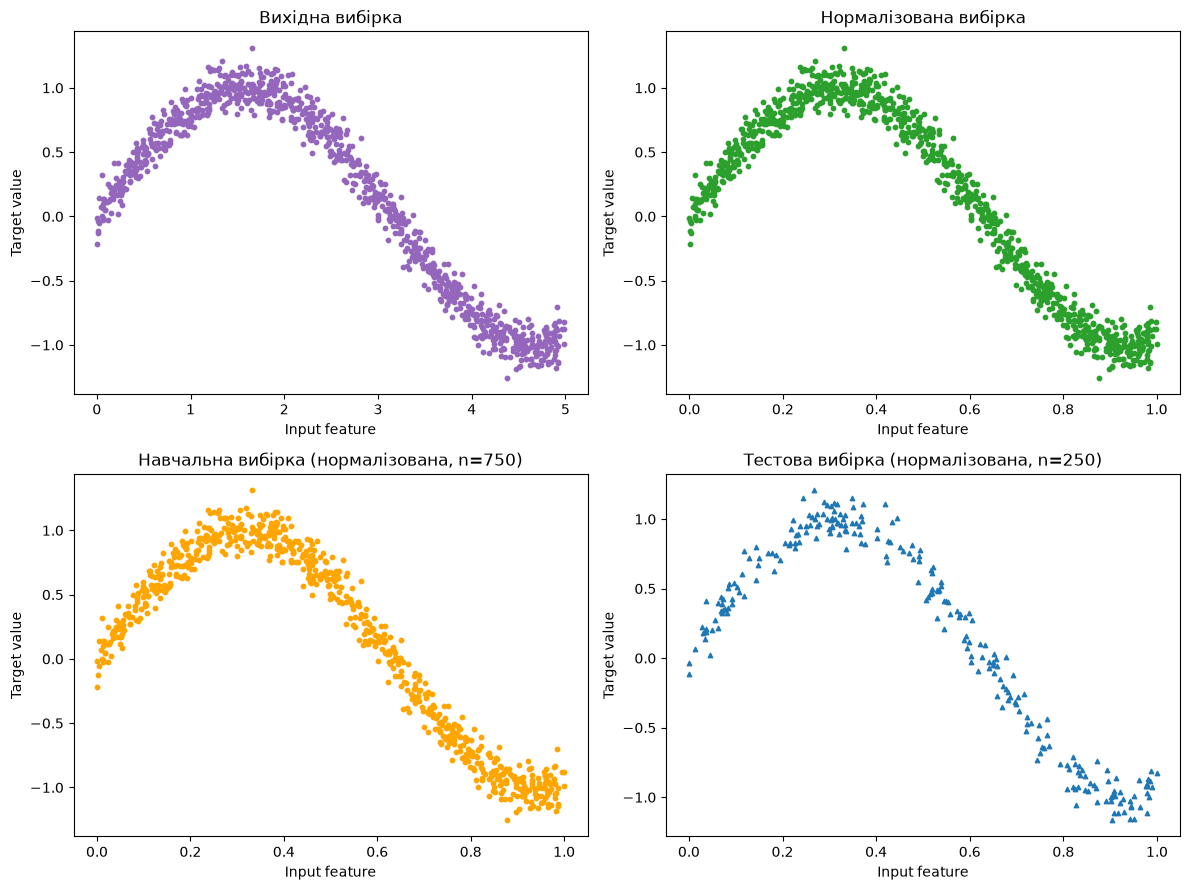

In [5]:
# Візуалізація даних: вихідна вибірка, нормалізована, train і test
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].scatter(X, y, s=10, color='tab:purple')
axes[0, 0].set_title('Вихідна вибірка')

axes[0, 1].scatter(X_scaled, y, s=10, color='tab:green')
axes[0, 1].set_title('Нормалізована вибірка')

axes[1, 0].scatter(X_train, y_train, s=10, color='orange')
axes[1, 0].set_title(f'Навчальна вибірка (нормалізована, n={len(X_train)})')

axes[1, 1].scatter(X_test, y_test, s=10, marker='^', color='tab:blue')
axes[1, 1].set_title(f'Тестова вибірка (нормалізована, n={len(X_test)})')

for ax in axes.ravel():
    ax.set_xlabel('Input feature')
    ax.set_ylabel('Target value')

plt.tight_layout()
plt.show()

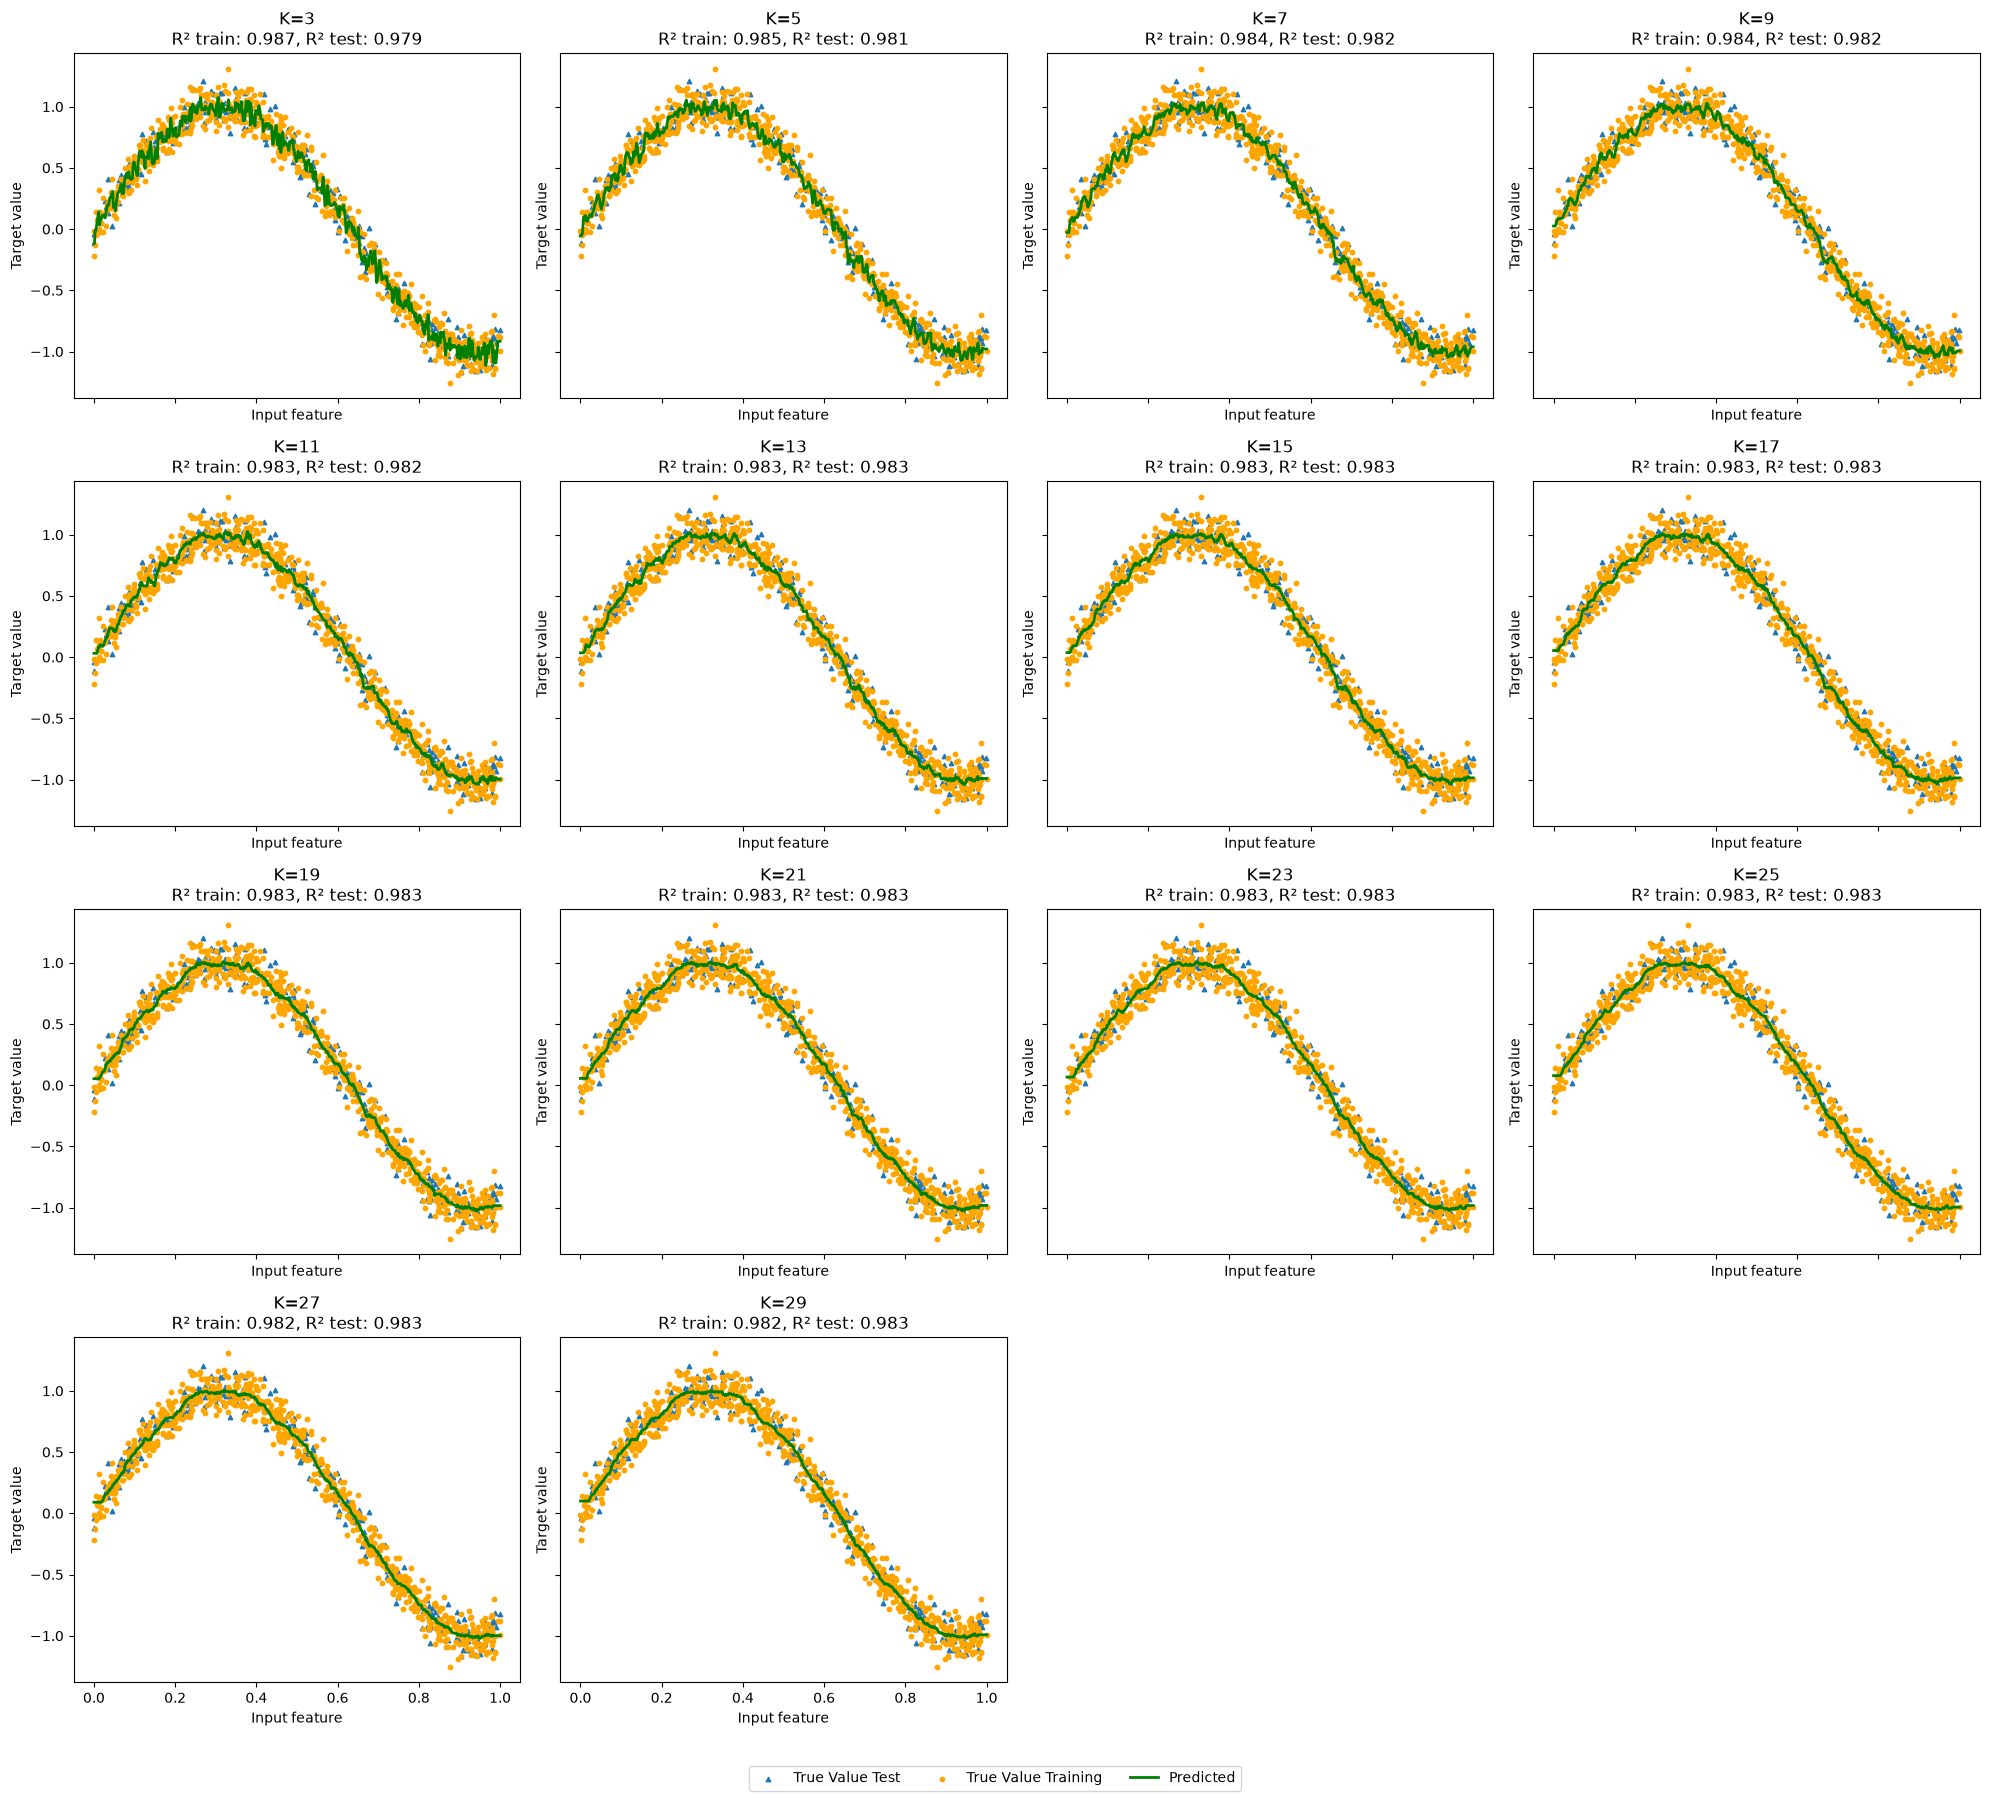

In [ ]:
# 4. Перебір непарних значень K від 3 до 30
k_values = list(range(3, 31, 2))
r2_scores = []

X_all = np.concatenate([X_train, X_test])
X_all_sorted = np.sort(X_all.ravel()).reshape(-1, 1)

n_cols = 4

n_rows = int(np.ceil(len(k_values) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4.5 * n_rows), sharex=True, sharey=True)
axes = axes.ravel()

for ax, k in zip(axes, k_values):
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train, y_train)

    y_pred_train = knn.predict(X_train)
    y_pred_test = knn.predict(X_test)
    r2_train = r2_score(y_train, y_pred_train)
    r2_test = r2_score(y_test, y_pred_test)
    r2_scores.append(r2_test)

    y_all_pred_sorted = knn.predict(X_all_sorted)

    ax.scatter(X_test, y_test, label='True Value Test', marker='^', color='tab:blue', s=10)
    ax.scatter(X_train, y_train, label='True Value Training', marker='o', color='orange', s=10)
    ax.plot(X_all_sorted, y_all_pred_sorted, color='green', label='Predicted', linewidth=2)
    ax.set_xlabel('Input feature')
    ax.set_ylabel('Target value')
    ax.set_title(f'K={k}\nR² train: {r2_train:.3f}, R² test: {r2_test:.3f}')

for ax in axes[len(k_values):]:
    ax.axis('off')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

In [7]:
# 5. Вибір найкращого K за максимальним R² 
best_k = k_values[np.argmax(r2_scores)]
print(f"Найкраще значення K: {best_k}")
print(f"Найвищий коефіцієнт детермінації (R²): {max(r2_scores):.4f}")

Найкраще значення K: 21
Найвищий коефіцієнт детермінації (R²): 0.9833


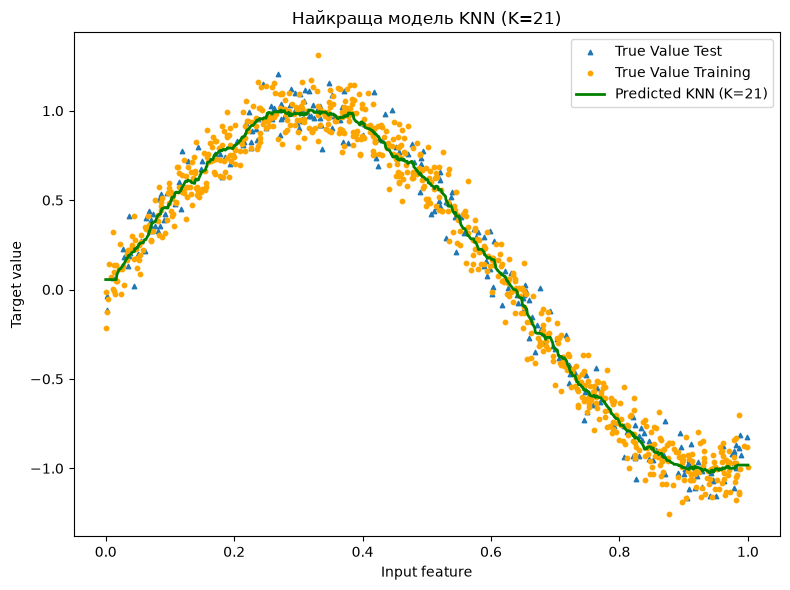

In [8]:
# 6. Візуалізація найкращої моделі
knn_best = KNeighborsRegressor(n_neighbors=best_k)
knn_best.fit(X_train, y_train)
y_best = knn_best.predict(np.concatenate([X_train, X_test]))
X_all = np.concatenate([X_train, X_test])
X_all_sorted = np.sort(X_all.ravel()).reshape(-1, 1)
y_best_sorted = knn_best.predict(X_all_sorted)

plt.figure(figsize=(8, 6))
plt.scatter(X_test, y_test, label='True Value Test', marker='^', color='tab:blue', s=10)
plt.scatter(X_train, y_train, label='True Value Training', marker='o', color='orange', s=10)
plt.plot(X_all_sorted, y_best_sorted, color='green', label=f'Predicted KNN (K={best_k})', linewidth=2)
plt.xlabel('Input feature')
plt.ylabel('Target value')
plt.title(f'Найкраща модель KNN (K={best_k})')
plt.legend()
plt.tight_layout()
plt.show()